In [1]:
import sys,os
os.environ['pRT_input_data_path'] = '/Users/nasedkin/python-packages/petitRADTRANS/petitRADTRANS/input_data/'
os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
#from numba import jit
from jax import config
config.update("jax_enable_x64", True)
import jax.numpy as jnp
from jax import grad, jit, vmap, lax
import petitRADTRANS.nat_cst as nc 
from petitRADTRANS import fort_spec as fs
from petitRADTRANS import Radtrans
from petitRADTRANS.retrieval.parameter import Parameter
from petitRADTRANS.retrieval.models import emission_model_diseq, guillot_emission
import petitRADTRANS.retrieval.plot_style as ps
import matplotlib.pyplot as plt
import copy as cp
pressures = 1e6*np.logspace(-6,3,20)
grav = 10**4
total_kap = np.ones((16,50,2,20))
total_kap_T = np.ones((16,50,2,20)).T
path_input_data = "/Users/nasedkin/python-packages/petitRADTRANS/petitRADTRANS/input_data/"
buffer = np.genfromtxt(os.path.join(path_input_data, 'opa_input_files', 'g_comb_grid.dat'))

def calc_tau_g_tot_ck_py(gravity,press,total_kappa):
    """
    calc_tau_g_tot_ck


    Args:
        gravity (float): surface gravity in cgs units
        press (np.ndarray): pressure in each level in cgs
        total_kappa (np.ndarray): total_kappa(g_len,freq_len,N_species,struc_len)

    Returns:
        tau: total correlated k opacity
    """
    tau = np.zeros(total_kappa.shape)
    struc_len = total_kappa.shape[3]
    for i_struc in range(1,struc_len):
        tau[i_struc] = tau[i_struc-1] +\
             (total_kappa[i_struc]+total_kappa[i_struc-1])\
             /2.0/gravity*(press[i_struc]-press[i_struc-1])
    return tau


/Users/nasedkin/anaconda3/envs/pRTUpdate/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Initiating species v0.5.5... [DONE]
A new version (0.6.0) is available!
Want to stay informed about updates?
Please have a look at the Github page:
https://github.com/tomasstolker/species
Database: /Users/nasedkin/python-packages/petitRADTRANS/species_database.hdf5
Data folder: /Users/nasedkin/python-packages/petitRADTRANS/data
Working folder: /Users/nasedkin/python-packages/petitRADTRANS
Grid interpolation method: linear
Using pRT Plotting style!


In [5]:
print(buffer)

[[0.01786956 0.04555284]
 [0.09150009 0.10007147]
 [0.21351042 0.14116799]
 [0.36745441 0.1632077 ]
 [0.53254559 0.1632077 ]
 [0.68648958 0.14116799]
 [0.80849991 0.10007147]
 [0.88213044 0.04555284]
 [0.90198551 0.00506143]
 [0.91016668 0.01111905]
 [0.92372338 0.01568533]
 [0.94082827 0.01813419]
 [0.95917173 0.01813419]
 [0.97627662 0.01568533]
 [0.98983332 0.01111905]
 [0.99801449 0.00506143]]


In [6]:
%timeit calc_tau_g_tot_ck_py(grav,pressures,total_kap_T)


298 µs ± 7.39 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [7]:
@njit
def fast_ck(gravity,press,total_kappa):
    """
    calc_tau_g_tot_ck


    Args:
        gravity (float): surface gravity in cgs units
        press (np.ndarray): pressure in each level in cgs
        total_kappa (np.ndarray): total_kappa(g_len,freq_len,N_species,struc_len)

    Returns:
        tau: total correlated k opacity
    """
    tau = np.zeros(total_kappa.shape)
    struc_len = total_kappa.shape[3]
    for i_struc in range(1,struc_len):
        tau[i_struc] = tau[i_struc-1] +\
             (total_kappa[i_struc]+total_kappa[i_struc-1])\
             /2.0/gravity*(press[i_struc]-press[i_struc-1])
    return tau
fast_ck(grav,pressures,total_kap_T)

NameError: name 'njit' is not defined

In [ ]:
%timeit fast_ck(grav,pressures,total_kap_T)


91.5 µs ± 5.18 µs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [ ]:
%timeit fs.calc_tau_g_tot_ck(grav,pressures,total_kap)
contopas = np.ones((50,20))
%timeit fs.calc_tau_g_tot_ck_scat(grav, pressures, total_kap[:,:,:1,:], True, contopas)

76.5 µs ± 3.62 µs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
122 µs ± 4.08 µs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [ ]:
jpressures = 1e6*jnp.logspace(-6,3,20)
jgrav = 10**4
jtotal_kap = jnp.ones((16,50,2,20))
jtotal_kap_T = jnp.ones((16,50,2,20)).T

@jit
def calc_trans_g_tot_ck(gravity,pressure,total_opacity):
    """_summary_

    Args:
        gravity (float): Surface gravity in cgs (cm/s^2)
        pressure (ndarray): 1D array of pressures in pascal
        total_opacity (ndarray): kappa, has shape (g_len, freq_len, press_len)
                                 This is the sum of all species' opacities, at 
                                 every c-k g coordinate, frequency and pressure.

    Returns:
        transmission: Tau, a 1D array of transmission coefficients for g, 
                      frequency and for every pressure level in the atmosphere.
    """
    transmission = jnp.zeros(total_opacity.shape)
    for i_struc in range(1,total_opacity.shape[3]):
        transmission = transmission.at[i_struc].set(transmission[i_struc-1] +\
                       (total_opacity[i_struc]+total_opacity[i_struc-1])\
                        /2.0/gravity*(pressure[i_struc]-pressure[i_struc-1]))
    return transmission

@jit
def calc_photon_destruction_prob(gravity,
                                 pressure,
                                 total_opacity_in,
                                 continuum_opacity_scat_emis):
    """_summary_

    Args:
        gravity (float): Surface gravity in cgs (cm/s^2)
        pressure (ndarray):1D array of pressures in pascal
        total_opacity_in (ndarray): kappa, has shape (g_len, freq_len, press_len)
                                    This is the sum of all species' opacities, at 
                                    every c-k g coordinate, frequency and pressure.
        continuum_opacity_scat_emis (ndarray): The continuum opacity, which is constant 
                                                in g, for every frequency and pressure.
                                                This includes clouds, Rayleigh and CIA
                                                opacities.

    Returns:
        photon_destruction_prob: probability that the photon DOESN'T leave the atmospheric layer
    """
    total_opacity = total_opacity_in[:,:,0,:]
    g_len = total_opacity_in.shape[0]
    photon_destruction_prob = jnp.ones(total_opacity.shape)
    for i_g in range(g_len):
        total_opacity = total_opacity.at[i_g].set(total_opacity[i_g] + continuum_opacity_scat_emis)
        photon_destruction_prob = photon_destruction_prob.at[i_g].set(continuum_opacity_scat_emis/total_opacity[i_g])
    photon_destruction_prob = 1 - photon_destruction_prob
    return photon_destruction_prob

@jit
def transmission_g_tot_ck_scat(gravity,
                          pressure,
                          total_opacity_in,
                          continuum_opacity_scattering_emis):
    """_summary_

    Args:
        gravity (_type_): _description_
        pressure (_type_): _description_
        total_opacity_in (_type_): _description_
        continuum_opacity_scattering_emis (_type_): _description_

    Returns:
        _type_: _description_
    """
    photon_destruction_prob = calc_photon_destruction_prob(gravity,
                                                           pressure,
                                                           total_opacity_in,
                                                           continuum_opacity_scattering_emis)
    transmission = calc_trans_g_tot_ck(gravity,
                                       pressure,
                                       total_opacity_in)
    return transmission, photon_destruction_prob

def _rosseland_opacity(total_opacity, 
                         temperature, 
                         w_gauss, 
                         border_freqs, 
                         do_scat_emis, 
                         continuum_opacity_scattering_emis):
    """_summary_

    Args:
        total_opacity (_type_): _description_
        temperature (_type_): _description_
        w_gauss (_type_): _description_
        border_freqs (_type_): _description_
        do_scat_emis (_type_): _description_
        continuum_opacity_scattering_emis (_type_): _description_

    Returns:
        _type_: _description_
    """
    g_len = total_opacity.shape[0]

    if do_scat_emis:
        total_opacity_use = total_opacity + continuum_opacity_scattering_emis[None,:,:]
    else:
        total_opacity_use = total_opacity

    kappa_rosse = calc_rosse_opa(total_opacity_use, 
                                     border_freqs, 
                                     temperature,
                                     w_gauss)
    return kappa_rosse
rosseland_opacity = jit(_rosseland_opacity,static_argnums=(4))

def _planck_opacity(total_opacity, 
                      temperature, 
                      w_gauss, 
                      border_freqs,
                      do_scat_emis, 
                      continuum_opacity_scattering_emis):
    """_summary_

    Args:
        total_opacity (_type_): _description_
        temperature (_type_): _description_
        w_gauss (_type_): _description_
        border_freqs (_type_): _description_
        do_scat_emis (_type_): _description_
        continuum_opacity_scattering_emis (_type_): _description_

    Returns:
        _type_: _description_
    """
    if do_scat_emis:
        total_opacity_use = total_opacity + continuum_opacity_scattering_emis[None,:,:]
    else:
        total_opacity_use = total_opacity
    kappa_planck = calc_planck_opa(total_opacity_use[:,:,:], 
                                   border_freqs, 
                                   temperature,
                                   w_gauss)
    return kappa_planck
planck_opacity = jit(_planck_opacity,static_argnums=(4))

@jit
def calc_rosse_opa(total_opacity,
                   border_freqs,
                   temperature,
                   w_gauss):
    """_summary_

    Args:
        total_opacity (_type_): _description_
        border_freqs (_type_): _description_
        temperature (_type_): _description_
        w_gauss (_type_): _description_

    Returns:
        _type_: _description_
    """
    diff_freqs = jnp.diff(border_freqs)
    B_nu_dT = star_planck_div_T(temperature, border_freqs)
    kappa_rosse = jnp.sum(B_nu_dT *\
                          jnp.sum(w_gauss[:,None,None]/total_opacity[:,:-1,:],axis=0) *\
                          diff_freqs[:,None],axis=0)
    numerator = jnp.sum(B_nu_dT * diff_freqs[:,None], axis = 0)

    return numerator/kappa_rosse

@jit
def calc_planck_opa(total_opacity,
                    border_freqs,
                    temperature,
                    w_gauss):
    """_summary_

    Args:
        total_opacity (_type_): _description_
        border_freqs (_type_): _description_
        temperature (_type_): _description_
        w_gauss (_type_): _description_

    Returns:
        _type_: _description_
    """
    diff_freqs = jnp.diff(border_freqs)
    B_nu = star_planck(temperature,border_freqs)

    kappa_planck= jnp.sum(B_nu *jnp.sum(w_gauss[:,None,None]/total_opacity[:,:-1,:],axis=0) *diff_freqs[:,None],axis=0)
    norm = jnp.sum(B_nu * diff_freqs[:,None], axis = 0)
    return kappa_planck / norm

@jit
def flux_ck_contribution(frequency,
                         transmission,
                         temperature,
                         scat_angle,
                         w_gauss_scat_angle,
                         w_gauss):
    """_summary_

    Args:
        frequency (_type_): _description_
        transmission (_type_): _description_
        temperature (_type_): _description_
        scat_angle (_type_): mu, the cosine of the scattering angle
        w_gauss_scat_angle (_type_): _description_
        w_gauss (_type_): _description_

    Returns:
        _type_: _description_
    """

    struct_shape = (frequency.shape[0],temperature.shape[0])
    flux = jnp.zeros(struct_shape[0])
    contr_em = jnp.zeros(struct_shape)

    for i_scat_angle in range(scat_angle.shape[0]):
        # Transmissions for a given incidence angle
        transm_mu = jnp.exp(-transmission/scat_angle[i_scat_angle])

        # Flux contribution from given scat_angle-angle

        #mean_transm = np.zeros((struct_shape[0],transmission.shape[2],struct_shape[1])
        mean_transm = jnp.sum(transm_mu* w_gauss[:, None, None, None], axis=0)
        transm_all = jnp.prod(mean_transm, axis=1)

        r = planck_f(temperature,frequency)
        # Do the actual radiative transport
        flux_mu = jnp.sum((r[:,:-1]+r[:,1:])*(transm_all[:,0:-1]-transm_all[:,1:])/2.0,axis=1)      
        flux_mu = jnp.add(flux_mu,r[:,struct_shape[1]]*transm_all[:,struct_shape[1]])

        contr_em = contr_em.at[:,:-1].add((r[:,:-1]+r[:,1:])*(transm_all[:,0:-1]-transm_all[:,1:]) *\
                                           scat_angle[i_scat_angle]*w_gauss_scat_angle[i_scat_angle])     
        contr_em = contr_em.at[:,-1].add(2.0*r[:,struct_shape[1]] * transm_all[:,struct_shape[1]] *\
                                          scat_angle[i_scat_angle]*w_gauss_scat_angle[i_scat_angle])

        # angle integ, factor 1/2 needed for flux calc. from upward pointing intensity
        flux = jnp.add(flux, flux_mu/2.0*scat_angle[i_scat_angle]*w_gauss_scat_angle[i_scat_angle])

    #Normalization
    flux = flux*4.0*jnp.pi
    contr_em = contr_em.T
    contr_em = jnp.divide(contr_em,jnp.sum(contr_em,axis=0))
    return flux, contr_em

@jit
def flux_ck(frequency,
            transmission,
            temperature,
            scat_angle,
            w_gauss_scat_angle,
            w_gauss):
    """_summary_

    Args:
        frequency (ndarray): shape (len_freq)
        transmission (ndarray): shape (len_g, len_freq, len_spec, len_temp))
        temperature (ndarray): shape (len_temp)
        scat_angle (ndarray): shape (len_scatter)
        w_gauss_scat_angle (ndarray): shape (len_scatter)
        w_gauss (ndarray): shape (len_scatter)

    Returns:
        flux: shape (len_freq)
    """
    struct_shape = (frequency.shape[0],temperature.shape[0])
    flux = jnp.zeros(struct_shape[0])
    for i_scat_angle in range(scat_angle.shape[0]):
        # Transmissions for a given incidence angle
        transm_mu= jnp.exp(-transmission/scat_angle[i_scat_angle])
        mean_transm = jnp.sum(transm_mu* w_gauss[:, None, None, None], axis=0)
        transm_all = jnp.prod(mean_transm, axis=1)

        r = planck_f(temperature,frequency)
        # Do the actual radiative transport
        flux_mu = jnp.sum((r[:,:-1]+r[:,1:])*(transm_all[:,0:-1]-transm_all[:,1:])*0.5,axis=1)      
        flux_mu = jnp.add(flux_mu,r[:,struct_shape[1]]*transm_all[:,struct_shape[1]])
        #print(flux_mu.shape)
        # angle integ, factor 1/2 needed for flux calc. from upward pointing intensity
        flux = jnp.add(flux,flux_mu*0.5*scat_angle[i_scat_angle]*w_gauss_scat_angle[i_scat_angle])
    #Normalization
    return flux*4.0*jnp.pi

@jit
def planck_f(T,nu):
    """
    Calculates B_ν https://en.wikipedia.org/wiki/Planck%27s_law
    For every temperature and frequency provided.

    Args:
        T (ndarray): 1D array of temperature in Kelvin
        nu (ndarray): 1D array of frequencies in Hertz

    Returns:
        B_nu (ndarray): (len(nu),len(T)) matrix of the spectral radiance (ie flux) as calculated from 
                        Planck's law for each frequency and temperature.
    """
    T_use = jnp.tile(T,(nu.shape[0],1))
    buffer = 2.0*nc.h*nu[:,None]**3/nc.c**2
    B_nu = buffer / (jnp.exp(nc.h*nu[:,None]/(nc.kB*T_use))-1.0)
    return B_nu

@jit
def star_planck_div_T(T,nu):
    """
    Calculates the gradient of B_ν https://en.wikipedia.org/wiki/Planck%27s_law
    wrt Temperature every temperature and frequency provided.

    Args:
        T (ndarray): 1D array of temperature in Kelvin
        nu (ndarray): 1D array of frequencies in Hertz

    Returns:
        B_nu_dT (ndarray): (len(nu),len(T)) matrix of the derivative of the spectral radiance (ie flux)  
                           as calculated from Planck's law for each frequency and temperature.
    """
    nu_use = (nu[:-1]+nu[1:])/2
    T_use = jnp.tile(T,(nu_use.shape[0],1))
    buffer = 2.0*nc.h**2.0*nu_use[:,None]**4/nc.c**2
    B_nu_dT = buffer/ ((jnp.exp(nc.h*nu_use[:,None]/(nc.kB*T_use*2.0))-jnp.exp(-nc.h*nu_use[:,None]/(nc.kB*T_use*2.0)))**2)/(nc.kB*T_use**2)
    return B_nu_dT

@jit
def star_planck(T,nu):
    """
    Calculates B_ν https://en.wikipedia.org/wiki/Planck%27s_law
    For every temperature and frequency provided. 
    Approximates the integral using Boole's method

    Args:
        T (ndarray): 1D array of temperature in Kelvin
        nu (ndarray): 1D array of frequencies in Hertz

    Returns:
        B_nu (ndarray): (len(nu),len(T)) matrix of the spectral radiance (ie flux) as calculated from 
                        Planck's law for each frequency and temperature.
    """
    frequency_len = nu.shape[0]
    bnus = []
    # Take mean using Boole's method
    for i in range(frequency_len-1):
        nu_large = jnp.max(nu[i:i+1])
        nu_small = jnp.min(nu[i:i+1])
        nu1 = nu_small
        nu2 = nu_small+1.0*(nu_large-nu_small)/4.0
        nu3 = nu_small+2.0*(nu_large-nu_small)/4.0
        nu4 = nu_small+3.0*(nu_large-nu_small)/4.0
        nu5 = nu_large
        val = 1.0/90.0*\
            ((7.0* 2.0*nc.h*nu1**3)/(nc.c**2.0*(jnp.exp(nc.h*nu1/(nc.kB*T))-1.0)) +\
            (32.0*2.0*nc.h*nu2**3)/(nc.c**2.0*(jnp.exp(nc.h*nu2/(nc.kB*T))-1.0)) +\
            (12.0*2.0*nc.h*nu3**3)/(nc.c**2.0*(jnp.exp(nc.h*nu3/(nc.kB*T))-1.0) )+\
            (32.0*2.0*nc.h*nu4**3)/(nc.c**2.0*(jnp.exp(nc.h*nu4/(nc.kB*T))-1.0)) +\
            (7.0* 2.0*nc.h*nu5**3)/(nc.c**2.0*(jnp.exp(nc.h*nu5/(nc.kB*T))-1.0)))
        bnus.append(val)
    B_nu = jnp.array(bnus)
    return B_nu


In [ ]:
#flux_mu = jnp.sum((r[:,:-1]+r[:,1:])*(jnp.diff(transm_all,axis=1))/2.0,axis=1)   
temps = jnp.linspace(500.0,5000.0,20)
temps2 = np.linspace(500.0,5000.0,20)

bnus = np.zeros(49)
nus = nc.c/(jnp.linspace(1,5,50)*1e-4)
nus2 = nc.c/(np.linspace(1,5,50)*1e-4)

jtotal_kap = jnp.ones((16,50,2,20))*jnp.linspace(0.1,10,50)[None,:,None,None]#[:,:,0,:]
jtotal_kap *= jnp.linspace(1e-4,1e-2,20)[None,None,None,:]#[:,:,0,:]

total_kap = np.ones((16,50,2,20))*np.linspace(0.1,10,50)[None,:,None,None]#[:,:,0,:]
total_kap *= np.linspace(1e-4,1e-2,20)[None,None,None,:]

jgrav_contopas = jnp.ones((50,20))
jwgauss = jnp.array(buffer[:,1])

jmus = jnp.ones(4)
mus = np.ones(4)
jw_gauss_mus = jnp.ones(4)*4
w_gauss_mus = np.ones(4)*4
b = flux_ck(nus,jtotal_kap,temps,jmus,jw_gauss_mus,jwgauss)
c,cont2 = fs.flux_ck(nus2,total_kap,temps2,mus,w_gauss_mus,buffer[:,1],False)
#print(b)
#print(c)
#print(cont1.shape,cont2.shape)
print((c-b)/c)
%timeit flux_ck(nus,jtotal_kap,temps,jmus,jw_gauss_mus,jwgauss)
%timeit fs.flux_ck(nus2,total_kap,temps2,mus,w_gauss_mus,buffer[:,1],False)

#%timeit flux_ck(nus,jtotal_kap,temps,jmus,jw_gauss_mus,jwgauss)
#%timeit fs.flux_ck(nus,jtotal_kap,temps,jmus,jw_gauss_mus,jwgauss,False)

#
#calc_kappa_rosseland(jtotal_kap,temps, jwgauss, nus, True, jgrav_contopas)

#%timeit fs.calc_kappa_rosseland(total_kap,temps2, buffer[:,1], nus2, True, contopas)
#%timeit calc_kappa_rosseland(jtotal_kap,temps, jwgauss, nus, True, jgrav_contopas)
#%timeit calc_kappa_rosseland(jtotal_kap,temps, jwgauss, nus,True, jgrav_contopas)
#%timeit fs.calc_kappa_rosseland(total_kap,temps2, buffer[:,1], nus2,True, contopas)


[-2.62345287e-07 -2.51558217e-07 -2.42474410e-07 -2.34737128e-07
 -2.28079870e-07 -2.22300119e-07 -2.17241618e-07 -2.12782142e-07
 -2.08824899e-07 -2.05292367e-07 -2.02121820e-07 -1.99262020e-07
 -1.96670751e-07 -1.94312952e-07 -1.92159285e-07 -1.90185035e-07
 -1.88369244e-07 -1.86694038e-07 -1.85144086e-07 -1.83706170e-07
 -1.82368837e-07 -1.81122120e-07 -1.79957304e-07 -1.78866742e-07
 -1.77843698e-07 -1.76882210e-07 -1.75976993e-07 -1.75123339e-07
 -1.74317045e-07 -1.73554349e-07 -1.72831867e-07 -1.72146557e-07
 -1.71495670e-07 -1.70876720e-07 -1.70287449e-07 -1.69725808e-07
 -1.69189929e-07 -1.68678105e-07 -1.68188779e-07 -1.67720520e-07
 -1.67272018e-07 -1.66842063e-07 -1.66429548e-07 -1.66033445e-07
 -1.65652810e-07 -1.65286766e-07 -1.64934500e-07 -1.64595261e-07
 -1.64268347e-07 -1.63953107e-07]
885 µs ± 8.96 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
1.03 ms ± 36.7 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [ ]:
jgrav_contopas = jnp.ones((50,20))
jtotal_kap = jnp.ones((16,50,2,20))
jtotal_kap_T = jnp.ones((16,50,2,20)).T
transmission_g_tot_ck_scat(jgrav,jpressures,jtotal_kap,jgrav_contopas)

calc_trans_g_tot_ck(grav,pressures,total_kap_T)
%timeit calc_trans_g_tot_ck(jgrav,jpressures,jtotal_kap_T)


146 µs ± 7.92 µs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [ ]:
jtotal_kap = jtotal_kap_T[:,:1,:,:].T
contopas = np.ones((50,20))

a1,b1 = transmission_g_tot_ck_scat(jgrav,jpressures,jtotal_kap,jgrav_contopas)
%timeit transmission_g_tot_ck_scat(jgrav,jpressures,jtotal_kap,jgrav_contopas)

194 µs ± 4 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [ ]:
jtotal_kap = jnp.ones((16,50,2,20))*jnp.linspace(0.1,10,50)[None,:,None,None]#[:,:,0,:]
jtotal_kap *= jnp.linspace(1e-4,1e-2,20)[None,None,None,:]#[:,:,0,:]

total_kap = np.ones((16,50,2,20))*np.linspace(0.1,10,50)[None,:,None,None]#[:,:,0,:]
total_kap *= np.linspace(1e-4,1e-2,20)[None,None,None,:]
contopas = np.ones((50,20))
#print(jtotal_kap-total_kap)
out1 = _rosseland_opacity(jtotal_kap[:,:,0,:], temps, jwgauss, nus, True, jgrav_contopas)
out2 = fs.calc_kappa_rosseland(total_kap[:,:,0,:], temps2, buffer[:,1], nus2, True, contopas)
print(out1,out2)

[1.00072577 1.00371671 1.00558288 1.00666259 1.00727981 1.00767223
 1.007978   1.00826501 1.00856257 1.00888145 1.00922415 1.00958971
 1.00997595 1.01038038 1.01080063 1.01123456 1.01168028 1.01213621
 1.01260097 1.01307338] [1.00093545 1.00473941 1.00680935 1.00782898 1.00832542 1.00860448
 1.00882082 1.00904201 1.0092929  1.00957972 1.00990129 1.01025395
 1.01063352 1.01103607 1.01145816 1.01189684 1.01234967 1.01281456
 1.01328981 1.01377396]


In [ ]:
vec1 = np.ones((16,50,2,20))
vec2 = np.ones(16)*2
ans = np.zeros((50,2,20))
for i in range(50):
    for j in range(2):
        for k in range(20):
            ans[i,j,k] = np.sum(vec1[:,i,j,k]*vec2)
print(ans.shape)
print(ans)


(50, 2, 20)
[[[32. 32. 32. ... 32. 32. 32.]
  [32. 32. 32. ... 32. 32. 32.]]

 [[32. 32. 32. ... 32. 32. 32.]
  [32. 32. 32. ... 32. 32. 32.]]

 [[32. 32. 32. ... 32. 32. 32.]
  [32. 32. 32. ... 32. 32. 32.]]

 ...

 [[32. 32. 32. ... 32. 32. 32.]
  [32. 32. 32. ... 32. 32. 32.]]

 [[32. 32. 32. ... 32. 32. 32.]
  [32. 32. 32. ... 32. 32. 32.]]

 [[32. 32. 32. ... 32. 32. 32.]
  [32. 32. 32. ... 32. 32. 32.]]]


In [ ]:
ans = np.sum(vec1 * vec2[:, None, None, None], axis=0)
print(ans.shape)
print(ans)


(50, 2, 20)
[[[32. 32. 32. ... 32. 32. 32.]
  [32. 32. 32. ... 32. 32. 32.]]

 [[32. 32. 32. ... 32. 32. 32.]
  [32. 32. 32. ... 32. 32. 32.]]

 [[32. 32. 32. ... 32. 32. 32.]
  [32. 32. 32. ... 32. 32. 32.]]

 ...

 [[32. 32. 32. ... 32. 32. 32.]
  [32. 32. 32. ... 32. 32. 32.]]

 [[32. 32. 32. ... 32. 32. 32.]
  [32. 32. 32. ... 32. 32. 32.]]

 [[32. 32. 32. ... 32. 32. 32.]
  [32. 32. 32. ... 32. 32. 32.]]]


In [ ]:
def feautrier_rad_trans(border_freqs,
                        tau_approx_scat,
                        temperature,
                        mu,
                        w_gauss_mu,
                        w_gauss_ck,
                        photon_destruct_in,
                        surf_refl,
                        surf_emi,
                        I_star_0,
                        geom,
                        mu_star):
    
    # Lengths of arrays
    freq_len_bounded = border_freqs.shape[0] - 1
    struc_len = temperature.shape[0]
    N_mu = mu.shape[0]
    g_len = w_gauss_ck.shape[0]

    # Definitions
    I_plus_surface = jnp.zeros((N_mu,g_len,freq_len_bounded))
    I_minus = 0.0

    GCM_read = False
    iter_scat = 1000

    source = jnp.zeros((g_len,freq_len_bounded,struc_len))
    flux_old = jnp.zeros((freq_len_bounded))
    flux = jnp.zeros((freq_len_bounded))
    source_planet_scat_n = jnp.zeros((g_len,freq_len_bounded,struc_len))
    source_planet_scat_n1 = jnp.zeros((g_len,freq_len_bounded,struc_len))
    source_planet_scat_n2 = jnp.zeros((g_len,freq_len_bounded,struc_len))
    source_planet_scat_n3 = jnp.zeros((g_len,freq_len_bounded,struc_len))

    photon_destruct = photon_destruct_in

    # DO THE STELLAR ATTENUATION CALCULATION
    J_star_ini = jnp.zeros((g_len,freq_len_bounded,struc_len))
    I_star_calc = jnp.zeros((g_len,N_mu,struc_len,freq_len_bounded))
    plancks = jnp.zeros((struc_len,freq_len_bounded))
    a = jnp.zeros((struc_len,N_mu))
    b = jnp.zeros((struc_len,N_mu))
    c= jnp.zeros((struc_len,N_mu))
    r= jnp.zeros(struc_len)
    I_J=jnp.zeros((struc_len,N_mu))
    I_H=jnp.zeros((struc_len,N_mu))
    J_bol = jnp.zeros(struc_len)

    lambda_loc = jnp.zeros((g_len,freq_len_bounded,struc_len))
    J_planet_scat = jnp.zeros((g_len,freq_len_bounded,struc_len))
    inv_del_tau_min = 1e10
    J_bol = J_bol.at[1].set(0) #jnp.zeros(struc_len)
    I_GCM = jnp.zeros((N_mu,freq_len_bounded))

    planck= jnp.zeros(struc_len)
    for i in range(freq_len_bounded):
        # Irradiation treatment
        # Dayside ave: multiply flux by 1/2.
        # Planet ave: multiply flux by 1/4
        for i_mu in range(N_mu):
            if  geom ==0:
                I_star_calc = I_star_calc.at[:,i_mu,:,i].set(0.5* jnp.abs(I_star_0[i])*jnp.exp(-tau_approx_scat[:,i,:]/mu[i_mu]))
                J_star_ini = J_star_ini.at[:,i,:].set(J_star_ini[:,i,:]+0.5*I_star_calc[:,i_mu,:,i]*w_gauss_mu[i_mu])
            elif geom ==1:
                I_star_calc = I_star_calc.at[:,i_mu,:,i].set(0.25* jnp.abs(I_star_0[i])*jnp.exp(-tau_approx_scat[:,i,:]/mu[i_mu]))
                J_star_ini = J_star_ini.at[:,i,:].set(J_star_ini[:,i,:]+0.5*I_star_calc[:,i_mu,:,i]*w_gauss_mu[i_mu])
            elif geom==2:
                J_star_ini = J_star_ini.at[:,i,:].set(jnp.abs(I_star_0[i]/4.*jnp.exp(-tau_approx_scat[:,i,:]/mu_star)))
            else:
                print('Invalid geometry')

    for i in range(freq_len_bounded):
        r = planck_f_lr(temperature,border_freqs[i],border_freqs[i+1])
        plancks = plancks.at[:, i].set(r)
    photon_destruct = jnp.where(photon_destruct_in<1e-10,1e-10,photon_destruct)
    for i_iter_scat in range(iter_scat):
        J_bol = jnp.zeros(struc_len)
        I_GCM = I_GCM.at[:,i].multiply(0.0)

        flux_old = flux
        for i in range(freq_len_bounded):
            r = plancks[:, i]
            planck = plancks[:, i]
            for l in range(g_len):
                if i_iter_scat == 0:
                    source = source.at[l,i,:].set(photon_destruct[l,i,:]*r +  (1.0-photon_destruct[l,i,:])*J_star_ini[l,i,:])
                else:
                    r = source[l,i,:]
                for j in range(N_mu):
                    # Own boundary treatment
                    f1 = mu[j]/(tau_approx_scat[l,i,1]-tau_approx_scat[l,i,0])

                    # own test against instability
                    f1 = lax.select(f1 > inv_del_tau_min, inv_del_tau_min, f1)
                    f1 = lax.select(f1 != f1, inv_del_tau_min, f1)

                    b= b.at[0].set(1.0 + 2.0 * f1 * (1.0 + f1))
                    c = c.at[0].set(-2.0*f1**2.0)
                    a = a.at[0].set(0.0)

                    # Calculate the local approximate lambda iterator
                    lambda_loc = lambda_loc.at[l,i,1].add(w_gauss_mu[j]/(1.0 + 2.0 * f1 * (1.0 + f1)))

                    for k in range(1,struc_len-1):
                        f1 = 2.0*mu[j]/(tau_approx_scat[l,i,k+1]-tau_approx_scat[l,i,k-1])
                        f2 = mu[j]/(tau_approx_scat[l,i,k+1]-tau_approx_scat[l,i,k])
                        f3 = mu[j]/(tau_approx_scat[l,i,k]-tau_approx_scat[l,i,k-1])
                        
                        # own test against instability
                        f1 = lax.select(f1 > 0.5*inv_del_tau_min, 0.5*inv_del_tau_min, f1)
                        f1 = lax.select(f1 != f1, 0.5*inv_del_tau_min, f1)
                        f2 = lax.select(f2 > inv_del_tau_min, inv_del_tau_min, f2)
                        f2 = lax.select(f2 != f2, inv_del_tau_min, f2)
                        f3 = lax.select(f3 > inv_del_tau_min, inv_del_tau_min, f3)
                        f3 = lax.select(f3 != f3, inv_del_tau_min, f3)

                        b = b.at[k].set(1.0 + f1*(f2+f3))
                        c = c.at[k].set(-f1*f2)
                        a = a.at[k].set(-f1*f3)

                        # Calculate the local approximate lambda iterator
                        lambda_loc = lambda_loc.at[l,i,k].add(w_gauss_mu[j]/(1.0+f1*(f2+f3)))
                    # Own boundary treatment
                    f1 = mu[j]/(tau_approx_scat[l,i,struc_len]-tau_approx_scat[l,i,struc_len-1])

                    f1 = lax.select(f1 > inv_del_tau_min, inv_del_tau_min, f1)
                    f1 = lax.select(f1 != f1, inv_del_tau_min, f1)

                    # TEST PAUL SCAT
                    a = a.at[struc_len].set(0.0)
                    b = b.at[struc_len].set(1.0)
                    c = c.at[struc_len].set(0.0)

                    # r(struc_len) = I_J(struc_len) = 0.5[I_plus + I_minus]
                    # where I_plus is the light that goes downwards and
                    # I_minus is the light that goes upwards.
                    ################## ALWAYS NEEDED ##################
                    I_plus = I_plus_surface[j, l, i]

                    ############### EMISSION ONLY TERM ################
                    I_minus = surf_emi[i]*planck[struc_len] \
                        + surf_refl[i] * 2.0 * jnp.sum(I_plus_surface[:, l, i] * mu * w_gauss_mu)
                    ############### SURFACE SCATTERING ################
                    # ----> of the emitted/scattered atmospheric light
                    # + surf_refl(i) * SUM(I_plus_surface(:, l, i) * w_gauss_mu) # OLD PRE 091220
                    # ----> of the direct stellar beam (depends on geometry)

                    if  geom != 2:
                        I_minus = I_minus + surf_refl[i] \
                            * 2.0 * jnp.sum(I_star_calc[l,:, struc_len, i] * mu * w_gauss_mu)
                    else:
                        I_minus = I_minus + surf_refl[i] *J_star_ini[l,i,struc_len] * 4.0 * mu_star
                    #sum to get I_J
                    r = r.at[struc_len].set(0.5*(I_plus + I_minus))

                    # Calculate the local approximate lambda iterator
                    lambda_loc = lambda_loc.at[l,i,struc_len].add(w_gauss_mu[j]/(1.0 + 2.0*f1**2.0))

                    I_J = I_J.at[:,j].set(tridag_own(a[:,j],b[:,j],c[:,j],r))
                    I_H = I_H.at[1,j].set(-I_J[0,j])

                    for k in range(1,struc_len-1):
                        f1 = mu[j]/(tau_approx_scat[l,i,k+1]-tau_approx_scat[l,i,k])
                        f2 = mu[j]/(tau_approx_scat[l,i,k]-tau_approx_scat[l,i,k-1])

                        f1 = lax.select(f1 > inv_del_tau_min, inv_del_tau_min, f1)
                        f2 = lax.select(f2 > inv_del_tau_min, inv_del_tau_min, f2)
                        deriv1 = f1*(I_J[k+1,j]-I_J[k,j])
                        deriv2 = f2*(I_J[k,j]-I_J[k-1,j])
                        I_H = I_H.at[k,j].set(-(deriv1+deriv2)/2.0)

                        if (k == struc_len - 1):
                            I_plus_surface = I_plus_surface.at[j, l, i].set(I_J[struc_len,j]  - deriv1)

                    I_H = I_H.at[struc_len,j].set(0.0)
                J_bol_g = jnp.zeros(struc_len)

                for j in range(N_mu):
                    J_bol_g = J_bol_g + I_J[:,j] * w_gauss_mu[j]
                    flux= flux.at[i].add(-I_H[1,j]*mu[j]* 4.0 *jnp.pi * w_gauss_ck[l] * w_gauss_mu[j])

                # Save angle-dependent surface flux
                if GCM_read:
                    for j in range(N_mu):
                        I_GCM = I_GCM.at[j,i].add( - 2.0*I_H[1,j]*w_gauss_ck[l])
                J_planet_scat = J_planet_scat.at[l,i,:].set(J_bol_g)
        
        photon_destruct = jnp.where(photon_destruct < 1e-10, 1e-10, photon_destruct)
        for i in range(freq_len_bounded):
            r = planck_f_lr(temperature[1:struc_len],border_freqs[i],border_freqs[i+1])
            for l in range(g_len):
                source = source.at[l,i,:].set((photon_destruct[l,i,:]*r+(1.0-photon_destruct[l,i,:])* \
                    (J_star_ini[l,i,:]+J_planet_scat[l,i,:]-lambda_loc[l,i,:]*source[l,i,:])) / \
                    (1.0-(1.0-photon_destruct[l,i,:])*lambda_loc[l,i,:]))

        source_planet_scat_n3 = source_planet_scat_n2
        source_planet_scat_n2 = source_planet_scat_n1
        source_planet_scat_n1 = source_planet_scat_n
        source_planet_scat_n  = source

        if i_iter_scat%4 == 0:
            #write(*,*) 'Ng acceleration#' 
            # CHECK CHECK CHECK
            source = NG_source_approx(source_planet_scat_n,
                                      source_planet_scat_n1,
                                      source_planet_scat_n2,
                                      source_planet_scat_n3,)

        conv_val = jnp.max(jnp.abs((flux-flux_old)/flux))
        if ((conv_val < 1e-3) and (i_iter_scat > 9)):
            break

    # Calculate the contribution function.
    # Copied from flux_ck, here using "source" as the source function
    # (before it was the Planck function).
    struct_shape = (freq_len_bounded,temperature.shape[0])
    contr_em = jnp.zeros(struct_shape)

    # Let's ignore the contribution function for now.
    if False:
        for i_mu in range(mu.shape[0]):
            # Transmissions for a given incidence angle
            transm_mu = jnp.exp(-transmission/mu[i_mu])

            # Flux contribution from given mu-angle

            #mean_transm = np.zeros((struct_shape[0],transmission.shape[2],struct_shape[1])
            mean_transm = jnp.sum(transm_mu* w_gauss[:, None, None, None], axis=0)
            transm_all = jnp.prod(mean_transm, axis=1)
            r = jnp.sum(source*w_gauss_ck[:,None,None,None],axis = 0)
            #r = planck_f(temperature,frequency)
            # Do the actual radiative transport
            contr_em = contr_em.at[:,:-1].add((r[:,:-1]+r[:,1:])*(transm_all[:,0:-1]-transm_all[:,1:]) *\
                                            mu[i_mu]*w_gauss_mu[i_mu])     
            contr_em = contr_em.at[:,-1].add(2.0*r[:,struct_shape[1]] * transm_all[:,struct_shape[1]] *\
                                            mu[i_mu]*w_gauss_mu[i_mu])

            # angle integ, factor 1/2 needed for flux calc. from upward pointing intensity
        #Normalization
        contr_em = contr_em.T
        contr_em = jnp.divide(contr_em,jnp.sum(contr_em,axis=0))
    return source, contr_em
py_feautrier_rad_trans = jit(feautrier_rad_trans, static_argnames=('geom'))

@jit
def planck_f_lr(T,nul,nur):
    # calculate planck function between two frequencies
    B_nu = 0.0
    # Take mean using Boole's method
    nu_large = jnp.maximum(nul,nur)
    nu_small = jnp.minimum(nul,nur)
    nu1 = nu_small
    nu2 = nu_small+1.0*(nu_large-nu_small)/4.0
    nu3 = nu_small+2.0*(nu_large-nu_small)/4.0
    nu4 = nu_small+3.0*(nu_large-nu_small)/4.0
    nu5 = nu_large
    diff_nu = nu2-nu1
    B_nu = B_nu + 1.0/90.0*( \
        7.0* 2.0*nc.h*nu1**3.0/nc.c**2.0/(jnp.exp(nc.h*nu1/(nc.kB*T))-1.0) +\
        32.0*2.0*nc.h*nu2**3.0/nc.c**2.0/(jnp.exp(nc.h*nu2/(nc.kB*T))-1.0) +\
        12.0*2.0*nc.h*nu3**3.0/nc.c**2.0/(jnp.exp(nc.h*nu3/(nc.kB*T))-1.0) +\
        32.0*2.0*nc.h*nu4**3.0/nc.c**2.0/(jnp.exp(nc.h*nu4/(nc.kB*T))-1.0) +\
        7.0* 2.0*nc.h*nu5**3.0/nc.c**2.0/(jnp.exp(nc.h*nu5/(nc.kB*T))-1.0))
    return B_nu

@jit
def NG_source_approx(source_n,source_n1,source_n2,source_n3):
    N_g, freq_len_p_1,struc_len = source_n.shape
    source_buff = jnp.zeros((N_g,freq_len_p_1-1,struc_len))
    for i_freq in range(freq_len_p_1-1):
        for i_ng in range(N_g):
            tn = source_n[i_ng,i_freq,1:struc_len]
            tn1 = source_n1[i_ng,i_freq,1:struc_len]
            tn2 = source_n2[i_ng,i_freq,1:struc_len]
            tn3 = source_n3[i_ng,i_freq,1:struc_len]

            Q1 = tn - 2.0*tn1 + tn2
            Q2 = tn - tn1 - tn2 + tn3
            Q3 = tn - tn1

            # test
            Q1[1] = 0.0
            Q2[1] = 0.0
            Q3[1] = 0.0

            A1 = jnp.sum(Q1*Q1)
            A2 = jnp.sum(Q2*Q1)
            B1 = jnp.sum(Q1*Q2)
            B2 = jnp.sum(Q2*Q2)
            C1 = jnp.sum(Q1*Q3)
            C2 = jnp.sum(Q2*Q3)

            if ((jnp.abs(A1) >= 1e-250) and \
                (jnp.abs(A2) >=1e-250) and \
                (jnp.abs(B1) >=1e-250) and \
                (jnp.abs(B2) >=1e-250) and \
                (jnp.abs(C1) >=1e-250) and \
                (jnp.abs(C2) >=1e-250)):

                a = (C1*B2-C2*B1)/(A1*B2-A2*B1)
                b = (C2*A1-C1*A2)/(A1*B2-A2*B1)

                temp_buff = (1.0-a-b)*tn + a*tn1 + b*tn2
                temp_buff = jnp.where(temp_buff <= 0.0, 0.0, temp_buff)
                source_buff = source_buff.at[i_ng,i_freq,1:struc_len].set(temp_buff)
            else:
                source_buff = source_buff.at[i_ng,i_freq,1:struc_len].set(source[i_ng,i_freq,1:struc_len])
    source = source_buff
    return source

## Tri Diagonal Matrix Algorithm(a.k.a Thomas algorithm) solver
# https://gist.github.com/cbellei/8ab3ab8551b8dfc8b081c518ccd9ada9
@jit 
def tridag_own(a, b, c, d):
    '''
    TDMA solver, a b c d can be NumPy array type or Python list type.
    refer to http://en.wikipedia.org/wiki/Tridiagonal_matrix_algorithm
    and to http://www.cfd-online.com/Wiki/Tridiagonal_matrix_algorithm_-_TDMA_(Thomas_algorithm)
    '''
    nf = len(d) # number of equations
    ac, bc, cc, dc = map(jnp.array, (a, b, c, d)) # copy arrays
    for it in range(1, nf):
        mc = ac[it]/bc[it-1]
        bc = bc.at[it].add(- mc*cc[it-1])
        dc = dc.at[it].add(- mc*dc[it-1])
    xc = bc
    xc = xc.at[-1].set(dc[-1]/bc[-1])

    for il in range(nf-2, -1, -1):
        xc = xc.at[il].set((dc[il]-cc[il]*xc[il+1])/bc[il])
    return xc
    


In [1]:
import sys,os
os.environ['pRT_input_data_path'] = '/Users/nasedkin/python-packages/petitRADTRANS/petitRADTRANS/input_data/'
os.environ["OMP_NUM_THREADS"] = "1"
import numpy as np
#from numba import jit
from jax import config
config.update("jax_enable_x64", True)
import jax.numpy as jnp
from jax import grad, jit, vmap, lax
import petitRADTRANS.nat_cst as nc 
from petitRADTRANS import fort_spec as fs
from petitRADTRANS import Radtrans
from petitRADTRANS.retrieval.parameter import Parameter
from petitRADTRANS.retrieval.models import guillot_emission
import copy as cp

parameters = {}
parameters['log_g'] = Parameter('log_g', False, value = 4.00)
parameters['D_pl'] = Parameter('D_pl', False, value = 20.0*nc.pc)
parameters['R_pl'] = Parameter('R_pl', False, value = 1.0*nc.r_jup)
parameters['T_int'] = Parameter('T_int', False, value = 500)
parameters['T_equ'] = Parameter('T_equ', False, value = 100)
parameters['gamma'] = Parameter('gamma', False, value = 0.1)
parameters['log_kappa_IR'] = Parameter('log_kappa_IR', False, value = 0.1)

parameters['H2O_Exomol'] = Parameter('H2O_Exomol', False, value = -1.5)
parameters['CO_all_iso_HITEMP'] = Parameter('CO_all_iso_HITEMP', False, value = -1.3)

parameters['pressure_simple'] = Parameter('pressure_simple', False, value = 100)
parameters['pressure_scaling'] = Parameter('pressure_scaling', False, value = 10)
parameters['pressure_width'] = Parameter('pressure_width', False, value = 3)
species = ['H2O_Exomol', 'CO_all_iso_HITEMP']
rayleigh_species = ['H2', 'He']
continuum_opacities = ['H2-H2', 'H2-He']
#cloud_species = ["Fe(c)_cd","MgSiO3(c)_cd"]
cloud_species = []
pressures = np.logspace(-6,3,80)

atmosphere = Radtrans(line_species = cp.copy(species), \
                      rayleigh_species= cp.copy(rayleigh_species), \
                      continuum_opacities = cp.copy(continuum_opacities), \
                      cloud_species = cp.copy(cloud_species), \
                      mode='c-k', \
                      wlen_bords_micron = [1.0,1.5],
                      do_scat_emis = True)
atmosphere.setup_opa_structure(pressures)

/Users/nasedkin/anaconda3/envs/pRTUpdate/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Initiating species v0.5.5... [DONE]
A new version (0.6.0) is available!
Want to stay informed about updates?
Please have a look at the Github page:
https://github.com/tomasstolker/species
Database: /Users/nasedkin/python-packages/petitRADTRANS/species_database.hdf5
Data folder: /Users/nasedkin/python-packages/petitRADTRANS/data
Working folder: /Users/nasedkin/python-packages/petitRADTRANS
Grid interpolation method: linear
Emission scattering is enabled: enforcing test_ck_shuffle_comp = True


/Users/nasedkin/python-packages/petitRADTRANS/petitRADTRANS/radtrans.py:106: FutureWarning: pRT_input_data_path was set by an environment variable. In a future update, the path to the petitRADTRANS input_data will be set within a .ini file that will be automatically generated into the user home directory (OS agnostic), inside a .petitradtrans directory
  warnings.warn(f"pRT_input_data_path was set by an environment variable. In a future update, the path to "


  Read line opacities of H2O_Exomol...
 Done.
  Read line opacities of CO_all_iso_HITEMP...
 Done.

  Read CIA opacities for H2-H2...
  Read CIA opacities for H2-He...
Done.



In [4]:
flux = guillot_emission(atmosphere,parameters,AMR=False,PT_plot_mode=False)

dayside_ave
JAX: 1.41s
FORTRAN: 0.26s
(406,) (406,)


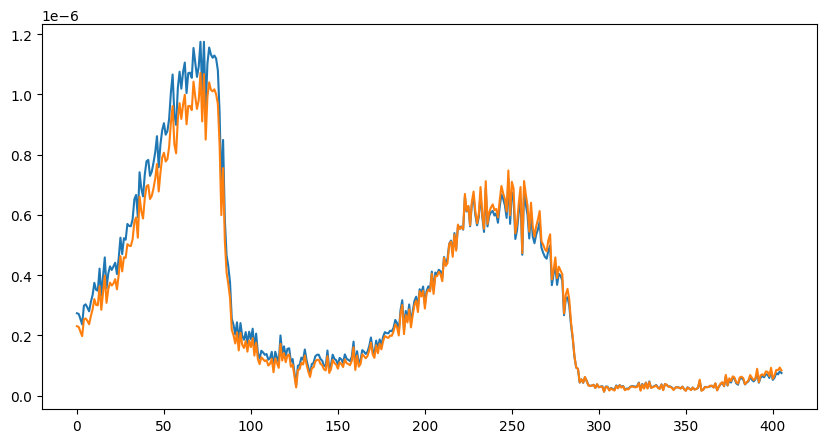

In [3]:

import matplotlib.pyplot as plt
jax_spec = np.load("jax_flux.npy")
spec = np.load("std_flux.npy")
fig,ax = plt.subplots(figsize = (10,5))
ax.plot(jax_spec/4)
ax.plot(spec)

In [ ]:
@jit
def tridag_wrapped(a,b,c,d):

    out = lax.map(tridag_own,)

@jit 
def tridag_own(a, b, c, d):
    '''
    TDMA solver, a b c d can be NumPy array type or Python list type.
    refer to http://en.wikipedia.org/wiki/Tridiagonal_matrix_algorithm
    and to http://www.cfd-online.com/Wiki/Tridiagonal_matrix_algorithm_-_TDMA_(Thomas_algorithm)
    '''
    nf = len(d) # number of equations
    ac,bc,cc,dc = lax.fori_loop(1,nf,internal_tridag,(a,b,c,d))     
    xc = bc
    xc = xc.at[-1].set(dc[-1]/bc[-1])
    xc = jnp.flip(xc)
    bc = jnp.flip(bc)
    cc = jnp.flip(cc)
    dc = jnp.flip(dc)
    xc,bc,cc,dc = lax.fori_loop(0,nf-1,internal_tridag_reverse,(xc,bc,cc,dc))
    return jnp.flip(xc)

@jit
def internal_tridag_reverse(il,val):
    xc,bc,cc,dc = val
    xc = xc.at[il].set((dc[il]-cc[il]*xc[il-1])/bc[il])
    return (xc,bc,cc,dc)

@jit
def internal_tridag(it,val):
    ac,bc,cc,dc = val
    mc = ac[it]/bc[it-1]
    bc = bc.at[it].add(- mc*cc[it-1])
    dc = dc.at[it].add(- mc*dc[it-1])
    return (ac,bc,cc,dc)

@jit
def solve_tridiag(ts, tus, tls, b):
  """Solve Tx=b where T is tridiagonal, w/diagonal ts, upper tus, lower tls."""
  prepend_zero = lambda x: jnp.append(jnp.zeros(1), x[:-1])
  fwd1 = lambda tu_, x: x[1] / (x[0] - x[2] * tu_)
  fwd2 = lambda b_, x: (x[0] - x[3] * b_) / (x[1] - x[3] * x[2])
  bwd1 = lambda x_, x: x[0] - x[1] * x_
  double = lambda f, args: (f(*args), f(*args))

  # forward pass
  _, tu_ = lax.scan(
      lambda tu_, x: double(fwd1, (tu_, x)),
      tus[0] / ts[0],
      (ts, tus, prepend_zero(tls)),
      unroll=32)
  _, b_ = lax.scan(
      lambda b_, x: double(fwd2, (b_, x)),
      b[0] / ts[0],
      (b, ts, prepend_zero(tu_), prepend_zero(tls)),
      unroll=32)

  # backsubstitution
  _, x_ = lax.scan(
      lambda x_, x: double(bwd1, (x_, x)), 0, (b_[::-1], tu_[::-1]), unroll=32)
  return x_[::-1]

@jit
def tridag_own_new(a,b,c,res):
    # I/O
    length = a.shape[0]
    # Internal variables
    buffer_vector = jnp.zeros(length )
    # Begin inversion
    buffer_scalar = b[0]

    solution = jnp.zeros(length)
    solution = solution.at[0].set(res[0] / buffer_scalar)

    for ind in range(1,length):
        buffer_vector = buffer_vector.at[ind].set(c[ind-1]/buffer_scalar)
        buffer_scalar = b[ind] - a[ind] * buffer_vector[ind]
        solution = solution.at[ind].set((res[ind] - \
            a[ind]*solution[ind-1])/buffer_scalar)

    for ind in range(length-1, 0, -1):
        solution = solution.at[ind].divide(- buffer_vector[ind+1] * solution[ind + 1])
    return solution



In [97]:
from scipy.linalg import solve_banded
#from jax.scipy import sparse
from scipy import sparse
ja = jnp.ones(80)
jb = jnp.ones(80)*2
jc = jnp.ones(80)*3
jd = jnp.ones(80)*2

a = np.ones(80)
b = np.ones(80)*2
c = np.ones(80)*3
d = np.ones(80)*2

a[0] = 0
c[-1] = 0

diag = jnp.diag(jd)
diags = [-1,0,1]                  # which diagonal each vector goes into
M = sparse.diags([ja,jb,jc],diags, shape = (80,80),format='csc') # create the matrix
def build_ab(a,b,c):
    ab = jnp.array([ja,jb,jc])
    return ab

banded = build_ab(a,b,c)
print(banded.shape)
@jit
def fast_fn(a,b,c,d):
    return lax.linalg.tridiagonal_solve(ja,jb,jc,diag)

def scipy_tridag(A,r):
    return solve_banded((1,1),A,r)

%timeit scipy_tridag(banded,d)
%timeit tridag_own(ja,jb,jc,jd)
%timeit fs.tridag_own(a,b,c,d)

(80,) (80,) (80,)
(3, 80)
16.3 µs ± 252 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
9.17 µs ± 89.1 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
1.27 µs ± 38.9 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


In [5]:
a = jnp.ones((10,20))*2
b = jnp.ones((10,20,3))
b = b.at[:,:,:].set(a[:,:,None])
print(b)

[[[2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]]

 [[2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]]

 [[2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]]

 [[2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 2. 2.]
  [2. 

In [10]:
def myFunc():
    return 5
def falseFunc():
    return 0
a = 3
a = lax.cond(False,lambda: myFunc(), lambda: 0)
print(a)

0
